# Projeto 2 — Classificação de notícias da BBC

Classificação de notícias da BBC em **5 categorias** (business, entertainment, politics, sport, tech) a partir do **texto livre** de cada notícia, comparando regressão logística treinada por gradiente descendente (LR-GD) e uma árvore de decisão (AD) implementada do zero.

**Base:** BBC News (Greene & Cunningham, 2006), com 2.225 notícias publicadas entre 2004 e 2005. Arquivo `data/bbc-text.csv`, com as colunas `category` (alvo) e `text`.

**Roteiro:** estudo introdutório → remoção de duplicatas → divisão 60/20/20 → TF-IDF + atributos estruturados → AD própria → LR-GD com 4 penalidades e busca de alpha → consistência 30/60/90% → 5 curvas → seleção pela validação → métricas no teste → 3 matrizes de confusão.

In [1]:
from pathlib import Path
import json
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import SGDClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Pasta do projeto: a que contém data/bbc-text.csv (funciona da raiz ou de subpastas).
_inicio = [Path(globals().get('__file__', Path.cwd() / 'x')).resolve().parent, Path.cwd()]
ROOT = next(p for base in _inicio for p in [base, *base.parents] if (p / 'data/bbc-text.csv').is_file())
DATASET = ROOT / 'data/bbc-text.csv'
OUT = ROOT / 'resultados'
FIG = OUT / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
TARGET, TEXT = 'category', 'text'
SEED = 42
SEEDS = [42, 43, 44]
FRACTIONS = [0.10, 0.30, 0.60, 0.90, 1.00]
MAX_DEPTH = 12
EPOCHS = 160
ALPHAS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
MAX_FEATURES = 1000   # vocabulário TF-IDF (limita o custo da árvore feita à mão)
ETA0 = 0.1            # taxa inicial do SGD (comparada com 0,01 e 0,5 na validação)
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit_learn': sklearn.__version__, 'scipy': scipy.__version__}
print(VERSIONS)
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True})

raw = pd.read_csv(DATASET)
print('Dimensões originais:', raw.shape)
display(raw.head())

{'python': '3.13.16', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit_learn': '1.9.1', 'scipy': '1.18.1'}
Dimensões originais: (2225, 2)


,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


## 1. Estudo introdutório

Distribuição das classes, tamanho dos textos, duplicatas e termos mais característicos de cada categoria.

Valores ausentes: 0
Textos duplicados: 99 | com rótulos diferentes: 0


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
business,510.0,334.0,138.0,142.0,236.0,303.0,396.0,912.0
entertainment,386.0,338.0,269.0,144.0,228.0,267.0,368.0,3570.0
politics,417.0,461.0,305.0,90.0,320.0,449.0,536.0,4492.0
sport,511.0,336.0,191.0,116.0,208.0,296.0,416.0,1671.0
tech,401.0,507.0,242.0,165.0,340.0,450.0,633.0,3007.0


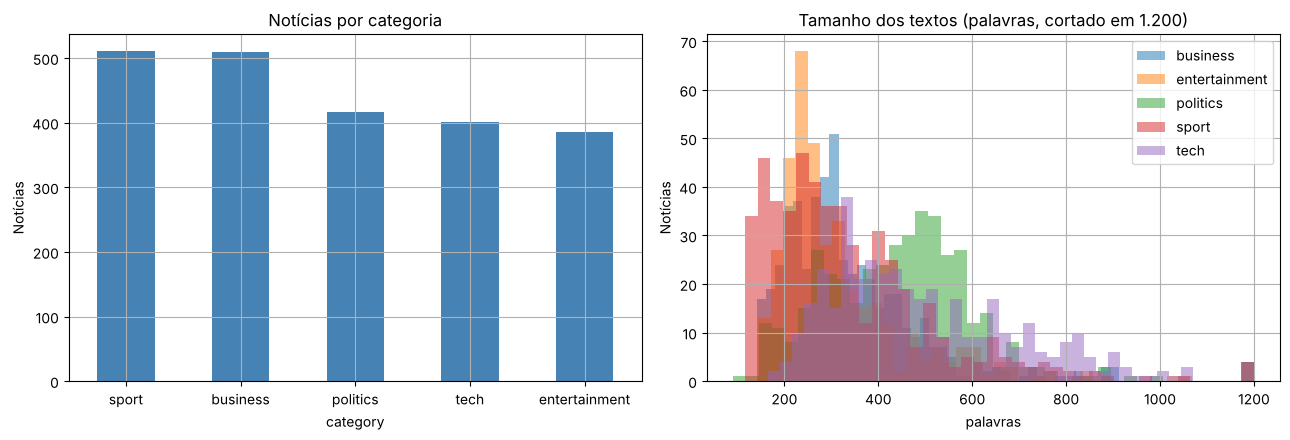

In [2]:
print('Valores ausentes:', int(raw.isna().sum().sum()))
dup = raw.duplicated(subset=TEXT)
print('Textos duplicados:', int(dup.sum()),
      '| com rótulos diferentes:', int((raw.groupby(TEXT)[TARGET].nunique() > 1).sum()))
words = raw[TEXT].str.split().str.len()
display(raw.assign(palavras=words).groupby(TARGET).palavras.describe().round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
raw[TARGET].value_counts().plot.bar(ax=axes[0], color='steelblue')
axes[0].set(title='Notícias por categoria', ylabel='Notícias'); axes[0].tick_params(axis='x', rotation=0)
for cat, group in raw.assign(palavras=words).groupby(TARGET):
    axes[1].hist(group.palavras.clip(upper=1200), bins=40, alpha=0.5, label=cat)
axes[1].set(title='Tamanho dos textos (palavras, cortado em 1.200)', xlabel='palavras', ylabel='Notícias')
axes[1].legend(); fig.tight_layout(); fig.savefig(FIG / 'eda.png', dpi=150); plt.show()

### 1.1 Remoção de duplicatas

A base tem notícias repetidas (mesmo texto, mesmo rótulo). Se uma cópia cair no treino e outra no teste, o modelo é avaliado em um texto que já viu, o que é vazamento de dados. Mantemos uma cópia de cada.

In [3]:
df = raw.drop_duplicates(subset=TEXT).reset_index(drop=True)
CLASSES = np.array(sorted(df[TARGET].unique()))
assert len(df) >= 2000 and len(CLASSES) >= 5
print('Após remover duplicatas:', df.shape)
dist = df[TARGET].value_counts().reindex(CLASSES)
display(dist.rename('quantidade').to_frame().assign(pct=lambda t: (t.quantidade / len(df) * 100).round(1)))
dist.rename('quantidade').to_csv(OUT / 'distribuicao_classes.csv')

Após remover duplicatas: (2126, 2)


,quantidade,pct
category,,
business,503,23.7
entertainment,369,17.4
politics,403,19.0
sport,504,23.7
tech,347,16.3


## 2. Partições

20% para teste e, dos 80% restantes, 25% para validação (20% do total), sobrando 60% para treino. Estratificado pela categoria, semente 42. Os subconjuntos de 10/30/60/90% do treino são estratificados e aninhados.

In [4]:
train_val, test = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.25, stratify=train_val[TARGET], random_state=SEED)
sets = [set(f.index) for f in (train, val, test)]
assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
display(pd.DataFrame({n: f[TARGET].value_counts().reindex(CLASSES)
                      for n, f in [('treino', train), ('validacao', val), ('teste', test)]}))
print('Tamanhos:', len(train), len(val), len(test))
y_train, y_val, y_test = (f[TARGET].to_numpy() for f in (train, val, test))


def subconjuntos_aninhados(frame, seed):
    pools, current = {1.0: frame}, frame
    for fraction in sorted([f for f in FRACTIONS if f < 1], reverse=True):
        current, _ = train_test_split(current, train_size=int(round(len(frame) * fraction)),
                                      stratify=current[TARGET], random_state=seed)
        pools[fraction] = current
    for small, large in zip(FRACTIONS[:-1], FRACTIONS[1:]):
        assert set(pools[small].index) <= set(pools[large].index)
    return pools

POOLS = {seed: subconjuntos_aninhados(train, seed) for seed in SEEDS}
display(pd.DataFrame([{'fracao_treino': f, 'n_treino': len(POOLS[SEED][f])} for f in FRACTIONS]))

,treino,validacao,teste
category,,,
business,301,101,101
entertainment,221,74,74
politics,242,80,81
sport,302,101,101
tech,209,69,69


Tamanhos: 1275 425 426


,fracao_treino,n_treino
0,0.1,128
1,0.3,382
2,0.6,765
3,0.9,1148
4,1.0,1275


## 3. Representação: TF-IDF + atributos estruturados

**Texto (não estruturado):** TF-IDF com unigramas e bigramas, minúsculas, sem stopwords em inglês, `min_df=2`, TF sublinear (1 + log tf), IDF suavizado e norma L2. O vocabulário fica limitado aos **1.000 termos mais frequentes**, para que a árvore própria rode em tempo razoável.

**Estruturados (opcionais no enunciado):** número de palavras e tamanho médio das palavras, convertidos para quantis em [0, 1]. Usamos quantis em vez de z-score porque os valores do TF-IDF são pequenos (≈ 0,05): com z-score, o tamanho do texto (até 17 desvios acima da média) dominava o gradiente e derrubava a LR de 0,94 para 0,80 de F1 na validação.

O vocabulário, o IDF e a padronização são ajustados **somente no subconjunto de treino** de cada modelo.

In [5]:
class Preprocessador:
    def fit(self, frame):
        self.tfidf = TfidfVectorizer(lowercase=True, stop_words='english', ngram_range=(1, 2),
                                     min_df=2, max_features=MAX_FEATURES, sublinear_tf=True)
        self.tfidf.fit(frame[TEXT])
        self.scaler = QuantileTransformer(n_quantiles=200, output_distribution='uniform').fit(self._estruturados(frame))
        return self

    @staticmethod
    def _estruturados(frame):
        tokens = frame[TEXT].str.split()
        return np.column_stack([tokens.str.len(), tokens.apply(lambda t: np.mean([len(w) for w in t]))])

    def transform(self, frame):
        return sparse.hstack([self.tfidf.transform(frame[TEXT]),
                              sparse.csr_matrix(self.scaler.transform(self._estruturados(frame)))]).tocsr()

    def fit_transform(self, frame):
        return self.fit(frame).transform(frame)

    def nomes(self):
        return list(self.tfidf.get_feature_names_out()) + ['n_palavras', 'tam_medio_palavra']


proc_demo = Preprocessador().fit(train)
Z_demo = proc_demo.transform(train)
print('Matriz de treino:', Z_demo.shape, '| esparsidade: %.1f%%' % (100 * (1 - Z_demo.nnz / np.prod(Z_demo.shape))))
# Termos com maior TF-IDF médio por categoria (somente treino).
vocab = proc_demo.tfidf.get_feature_names_out()
top = {c: vocab[np.asarray(Z_demo[y_train == c][:, :len(vocab)].mean(axis=0)).ravel().argsort()[::-1][:10]]
       for c in CLASSES}
display(pd.DataFrame(top))

Matriz de treino: (1275, 1002) | esparsidade: 93.0%


,business,entertainment,politics,sport,tech
0,said,film,mr,game,people
1,company,best,labour,win,technology
2,market,music,said,said,users
3,year,award,government,match,said
4,growth,awards,election,season,online
5,firm,said,party,cup,use
6,bank,star,blair,coach,computer
7,shares,tv,minister,team,software
8,2004,year,people,club,mobile
9,economy,actor,secretary,time,using


## 4. Árvore de decisão implementada do zero

CART binária multiclasse com Gini = 1 − Σ p(k)². Em cada nó, para cada atributo, ordena os valores, avalia todos os cortes entre valores distintos usando contagens cumulativas e escolhe o de maior redução de impureza. Treino (`fit`) e predição (`predict_proba`, `predict`) são próprios; `sklearn.tree` não é usado.

Critérios de parada: profundidade máxima, nó puro, mínimo de amostras por folha (8) e ganho mínimo. A folha guarda a proporção de cada classe e prediz a de maior proporção.

In [6]:
import numpy as np
from scipy import sparse


class ArvoreDecisaoPropria:
    """CART multiclasse: busca exata de cortes, Gini e predição próprias.

    Raiz na profundidade zero. Empates: menor índice de atributo/corte/classe.
    Não utiliza sklearn.tree. Conversão densa é limitada a esta base pequena.
    """

    def __init__(self, max_depth=12, min_samples_leaf=8, min_samples_split=2,
                 min_impurity_decrease=1e-10):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.min_impurity_decrease = min_impurity_decrease

    @staticmethod
    def _matrix(X):
        X = X.toarray() if sparse.issparse(X) else np.asarray(X, dtype=float)
        if X.ndim != 2 or not np.isfinite(X).all():
            raise ValueError('X deve ser matriz 2D finita, previamente imputada')
        return X

    def fit(self, X, y):
        X = self._matrix(X)
        y = np.asarray(y)
        if y.ndim != 1 or len(y) != len(X) or len(y) == 0:
            raise ValueError('y deve ser vetor não vazio alinhado a X')
        if self.max_depth < 0 or self.min_samples_leaf < 1 or self.min_samples_split < 2:
            raise ValueError('Parâmetros de profundidade/amostras inválidos')
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.n_features_in_ = X.shape[1]
        self.n_classes_ = len(self.classes_)
        self.node_count_ = 0
        self.depth_ = 0
        self.feature_importances_ = np.zeros(self.n_features_in_)
        self.root_ = self._grow(X, encoded, 0, len(y))
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        return self

    def _grow(self, X, y, depth, n_total):
        self.node_count_ += 1
        self.depth_ = max(self.depth_, depth)
        n = len(y)
        counts = np.bincount(y, minlength=self.n_classes_)
        impurity = 1.0 - np.sum((counts / n) ** 2)
        node = {'proba': counts / n, 'depth': depth, 'samples': n,
                'gini': impurity, 'feature': None}
        if (depth >= self.max_depth or impurity <= 1e-15
                or n < max(self.min_samples_split, 2 * self.min_samples_leaf)):
            return node
        best_gain = self.min_impurity_decrease
        best = None
        # Todas as fronteiras entre valores distintos são avaliadas.
        for feature in range(X.shape[1]):
            order = np.argsort(X[:, feature], kind='stable')
            values = X[order, feature]
            positions = np.flatnonzero(values[:-1] < values[1:]) + 1
            positions = positions[(positions >= self.min_samples_leaf)
                                  & (n - positions >= self.min_samples_leaf)]
            if not len(positions):
                continue
            cumulative = np.cumsum(np.eye(self.n_classes_)[y[order]], axis=0)
            left = cumulative[positions - 1]
            right = counts - left
            # Gini ponderado = 1 - (sum(L_k²)/nL + sum(R_k²)/nR)/n.
            weighted = 1 - (np.sum(left ** 2, axis=1) / positions
                            + np.sum(right ** 2, axis=1) / (n - positions)) / n
            gains = impurity - weighted
            i = int(np.argmax(gains))
            if gains[i] > best_gain + 1e-14:
                pos = int(positions[i])
                a, b = float(values[pos - 1]), float(values[pos])
                # Evita overflow com sinais opostos e arredondamento para b.
                threshold = a / 2 + b / 2 if a < 0 < b else a + (b - a) / 2
                if not a <= threshold < b:
                    threshold = a
                best_gain = float(gains[i])
                best = feature, float(threshold)
        if best is None:
            return node
        feature, threshold = best
        mask = X[:, feature] <= threshold
        self.feature_importances_[feature] += n / n_total * best_gain
        node.update(feature=feature, threshold=threshold,
                    left=self._grow(X[mask], y[mask], depth + 1, n_total),
                    right=self._grow(X[~mask], y[~mask], depth + 1, n_total))
        return node

    def predict_proba(self, X):
        if not hasattr(self, 'root_'):
            raise ValueError('Treine a árvore antes da predição')
        X = self._matrix(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('Quantidade de atributos diferente do treino')
        probabilities = np.empty((len(X), self.n_classes_))
        for i, row in enumerate(X):
            node = self.root_
            while node['feature'] is not None:
                node = node['left'] if row[node['feature']] <= node['threshold'] else node['right']
            probabilities[i] = node['proba']
        return probabilities

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return self.classes_[np.argmax(probabilities, axis=1)]


## 5. Regressão logística por gradiente descendente

`SGDClassifier(loss="log_loss")`: regressão logística otimizada por gradiente descendente estocástico, multiclasse um-contra-resto. Variantes: sem penalidade, Ridge (L2), Lasso (L1) e Elastic Net (50%/50%). Objetivo: média da log-loss + alpha × penalidade. Taxa inicial 0,1 com decaimento inverso, 160 épocas via `partial_fit` e média dos pesos. A taxa 0,1 foi comparada na validação com 0,01, que deixava o modelo subajustado (F1 de treino 0,95), e com 0,5, que dava resultado semelhante.

### 5.1 Busca do alpha

Para cada penalidade testamos alpha ∈ {1e-5, 1e-4, 1e-3, 1e-2, 1e-1}, treinando no treino completo e medindo F1 macro na **validação**. Em caso de empate, vence o maior alpha.

,familia,alpha,treino_f1_macro,validacao_f1_macro
0,LR Ridge,1e-05,0.9813,0.9668
1,LR Ridge,0.0001,0.9813,0.9668
2,LR Ridge,0.001,0.9710,0.9622
3,LR Ridge,0.01,0.9010,0.8775
4,LR Ridge,0.1,0.5720,0.5850
5,LR Lasso,1e-05,0.9820,0.9668
6,LR Lasso,0.0001,0.9781,0.9641
7,LR Lasso,0.001,0.9391,0.9259
8,LR Lasso,0.01,0.1722,0.1806
9,LR Lasso,0.1,0.0790,0.0724


Alpha escolhido: {'LR sem regularizacao': 0.0, 'LR Elastic Net': 1e-05, 'LR Lasso': 1e-05, 'LR Ridge': 0.0001}


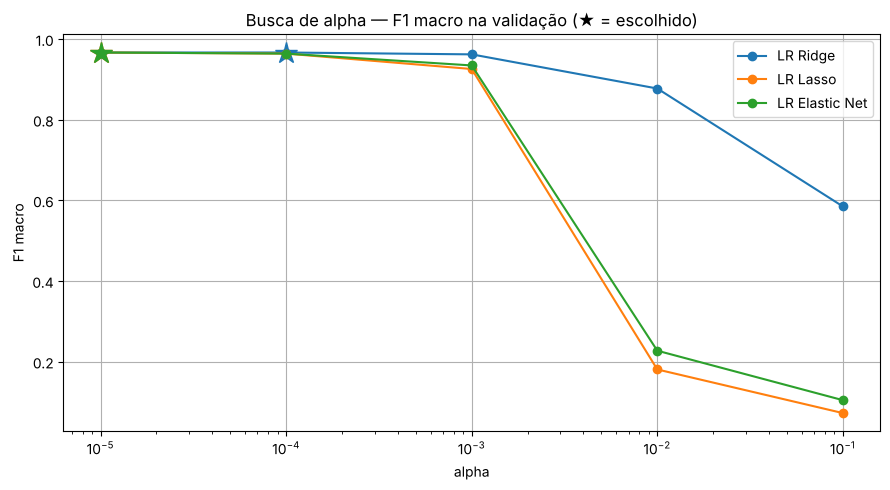

In [7]:
PENALTIES = {'LR sem regularizacao': None, 'LR Ridge': 'l2', 'LR Lasso': 'l1', 'LR Elastic Net': 'elasticnet'}
BEST_ALPHA = {'LR sem regularizacao': 0.0}


def treinar_lr(Z, y, family, seed, alpha=None):
    penalty = PENALTIES[family]
    alpha = BEST_ALPHA[family] if alpha is None else alpha
    model = SGDClassifier(loss='log_loss', penalty=penalty, alpha=0.0 if penalty is None else alpha,
                          l1_ratio=0.5, learning_rate='invscaling', eta0=ETA0, power_t=0.25,
                          average=True, random_state=seed)
    rng = np.random.default_rng(seed)
    for _ in range(EPOCHS):
        order = rng.permutation(len(y))
        model.partial_fit(Z[order], y[order], classes=CLASSES)
    return model


def metricas(y, pred):
    s = {'accuracy': accuracy_score(y, pred)}
    for avg in ['micro', 'macro']:
        s[f'precision_{avg}'] = precision_score(y, pred, labels=CLASSES, average=avg, zero_division=0)
        s[f'recall_{avg}'] = recall_score(y, pred, labels=CLASSES, average=avg, zero_division=0)
        s[f'f1_{avg}'] = f1_score(y, pred, labels=CLASSES, average=avg, zero_division=0)
    return s


proc_full = Preprocessador().fit(train)
Z_full, Z_val_full = proc_full.transform(train), proc_full.transform(val)
rows = []
for family, penalty in PENALTIES.items():
    if penalty is None:
        continue
    for alpha in ALPHAS:
        m = treinar_lr(Z_full, y_train, family, SEED, alpha)
        rows.append({'familia': family, 'alpha': alpha,
                     'treino_f1_macro': f1_score(y_train, m.predict(Z_full), average='macro'),
                     'validacao_f1_macro': f1_score(y_val, m.predict(Z_val_full), average='macro')})
alpha_search = pd.DataFrame(rows)
for family, g in alpha_search.groupby('familia'):
    BEST_ALPHA[family] = float(g.sort_values(['validacao_f1_macro', 'alpha'], ascending=[False, False]).iloc[0].alpha)
display(alpha_search.round(4).assign(alpha=alpha_search.alpha.map('{:g}'.format)))
print('Alpha escolhido:', BEST_ALPHA)
alpha_search.to_csv(OUT / 'busca_alpha.csv', index=False)

fig, ax = plt.subplots()
for family, g in alpha_search.groupby('familia', sort=False):
    line, = ax.plot(g.alpha, g.validacao_f1_macro, 'o-', label=family)
    ax.plot(BEST_ALPHA[family], g.set_index('alpha').loc[BEST_ALPHA[family], 'validacao_f1_macro'],
            '*', ms=16, color=line.get_color())
ax.set(xscale='log', title='Busca de alpha — F1 macro na validação (★ = escolhido)', xlabel='alpha', ylabel='F1 macro')
ax.legend(); fig.tight_layout(); fig.savefig(FIG / 'busca_alpha.png', dpi=150); plt.show()

## 6. Treinamento de todos os casos

- **Curva da AD:** profundidade 1 a 12 no treino completo. A melhor profundidade na validação é usada na consistência.
- **Curvas da LR:** 4 penalidades × 5 tamanhos de treino × 3 sementes.
- **Consistência da AD:** 30/60/90% do treino × 3 sementes.

Cada subconjunto ajusta seu próprio TF-IDF.

In [8]:
records, fitted = [], {}


def registrar(model, proc, sample, family, seed, fraction, kind, depth=None):
    key = f'{kind}|{family}|seed={seed}|fracao={fraction}|prof={depth}'
    row = {'modelo_id': key, 'familia': family, 'semente': seed, 'fracao_treino': fraction,
           'n_treino': len(sample), 'experimento': kind, 'max_depth': depth, 'alpha': BEST_ALPHA.get(family)}
    row.update({'treino_' + k: v for k, v in metricas(sample[TARGET], model.predict(proc.transform(sample))).items()})
    row.update({'validacao_' + k: v for k, v in metricas(y_val, model.predict(proc.transform(val))).items()})
    if family == 'AD propria':
        row.update(altura_real=model.depth_, nos=model.node_count_)
    records.append(row)
    fitted[key] = (model, proc)

start = time.perf_counter()
for depth in range(1, MAX_DEPTH + 1):
    tree = ArvoreDecisaoPropria(max_depth=depth, min_samples_leaf=8).fit(Z_full, y_train)
    registrar(tree, proc_full, train, 'AD propria', SEED, 1.0, 'curva_ad', depth)
tc = pd.DataFrame(records)
BEST_DEPTH = int(tc.sort_values(['validacao_f1_macro', 'max_depth'], ascending=[False, True]).iloc[0].max_depth)
print('Curva AD pronta (%.0fs). Profundidade escolhida: %d' % (time.perf_counter() - start, BEST_DEPTH))

for seed in SEEDS:
    for fraction in FRACTIONS:
        sample = POOLS[seed][fraction]
        proc = Preprocessador().fit(sample)
        Z, y = proc.transform(sample), sample[TARGET].to_numpy()
        for family in PENALTIES:
            registrar(treinar_lr(Z, y, family, seed), proc, sample, family, seed, fraction, 'curva_lr')
        if fraction in (0.30, 0.60, 0.90):
            tree = ArvoreDecisaoPropria(max_depth=BEST_DEPTH, min_samples_leaf=8).fit(Z, y)
            registrar(tree, proc, sample, 'AD propria', seed, fraction, 'consistencia_ad', BEST_DEPTH)
    print('Semente %d concluída (%.0fs)' % (seed, time.perf_counter() - start))

results = pd.DataFrame(records)
results['gap_f1_macro'] = results.treino_f1_macro - results.validacao_f1_macro
assert len(results) == 81
results.to_csv(OUT / 'treino_validacao_todos_casos.csv', index=False)

Curva AD pronta (20s). Profundidade escolhida: 10


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_data.py:2912: UserWarning: n_quantiles (200) is greater than the total number of samples (128). n_quantiles is set to n_samples.
  warnings.warn(


Semente 42 concluída (53s)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_data.py:2912: UserWarning: n_quantiles (200) is greater than the total number of samples (128). n_quantiles is set to n_samples.
  warnings.warn(


Semente 43 concluída (87s)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_data.py:2912: UserWarning: n_quantiles (200) is greater than the total number of samples (128). n_quantiles is set to n_samples.
  warnings.warn(


Semente 44 concluída (121s)


## 7. Consistência: 30%, 60% e 90% do treino

LR-GD Ridge (alpha escolhido) e AD própria (profundidade escolhida) nos mesmos subconjuntos e 3 sementes.

In [9]:
cons = results[((results.experimento == 'curva_lr') & (results.familia == 'LR Ridge')
                 & results.fracao_treino.isin([0.3, 0.6, 0.9])) | (results.experimento == 'consistencia_ad')]
summary = cons.groupby(['familia', 'fracao_treino', 'n_treino']).agg(
    treino_media=('treino_f1_macro', 'mean'), validacao_media=('validacao_f1_macro', 'mean'),
    validacao_desvio=('validacao_f1_macro', 'std'), gap_medio=('gap_f1_macro', 'mean')).reset_index()
display(summary.round(4))
summary.to_csv(OUT / 'consistencia_resumo.csv', index=False)

,familia,fracao_treino,n_treino,treino_media,validacao_media,validacao_desvio,gap_medio
0,AD propria,0.3,382,0.7831,0.6860,0.0193,0.0971
1,AD propria,0.6,765,0.7839,0.6820,0.0224,0.1019
2,AD propria,0.9,1148,0.7926,0.7175,0.0155,0.0751
3,LR Ridge,0.3,382,0.9886,0.9367,0.0097,0.0520
4,LR Ridge,0.6,765,0.9832,0.9572,0.0062,0.0260
5,LR Ridge,0.9,1148,0.9810,0.9620,0.0022,0.0190


## 8. Cinco curvas de aprendizado

- **Curvas 1–4 (LR-GD):** F1 macro de treino e validação × nº de instâncias de treino, média ± desvio de 3 sementes.
- **Curva 5 (AD):** F1 macro de treino e validação × profundidade máxima, de 1 até a altura limite de 12.

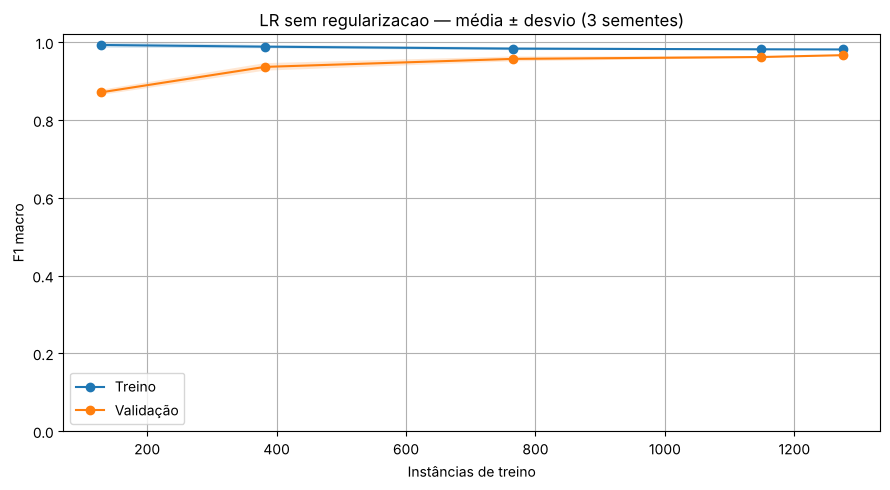

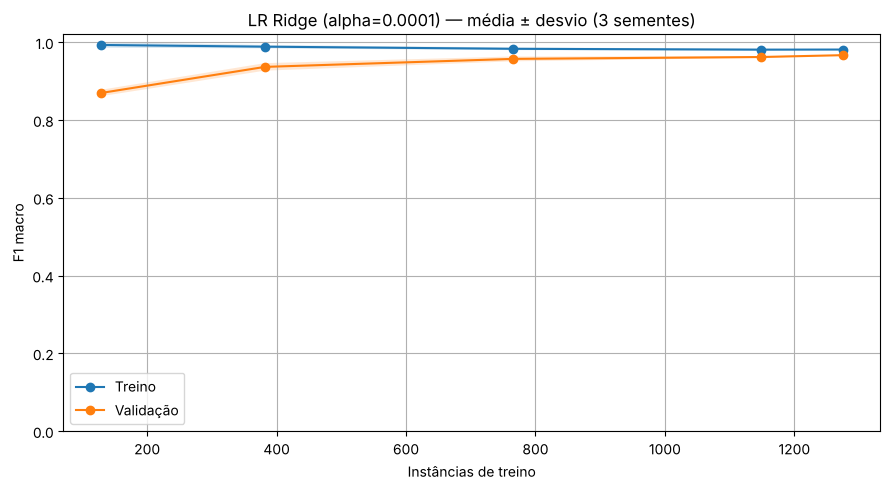

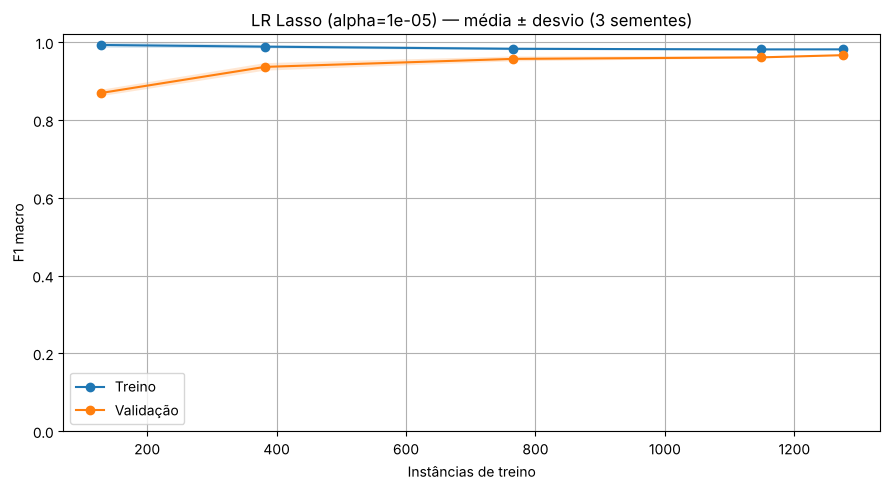

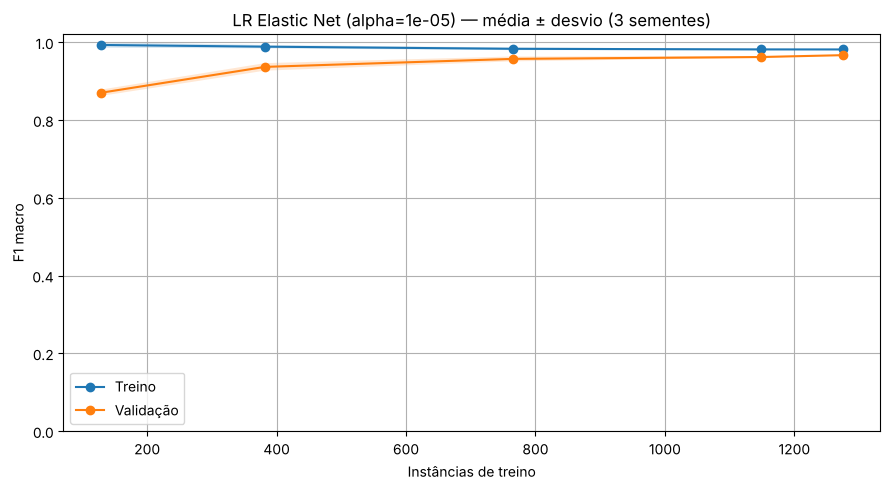

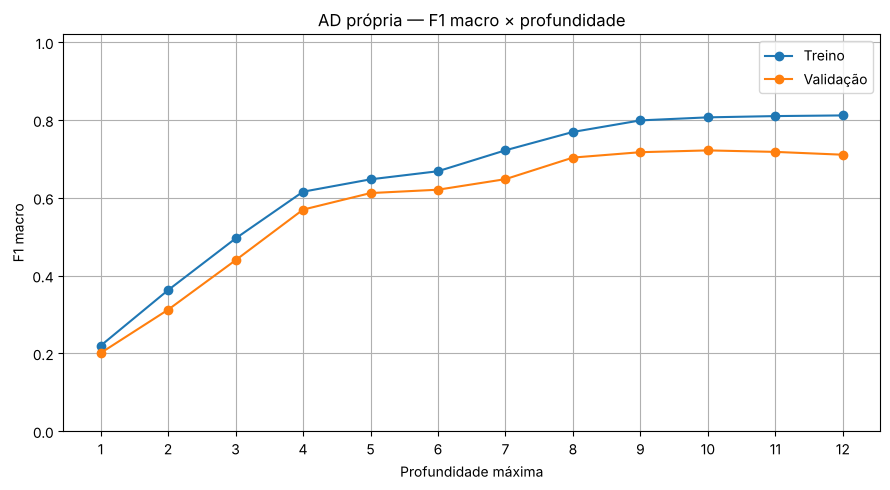

,max_depth,altura_real,nos,treino_f1_macro,validacao_f1_macro
0,1.0,1.0,3.0,0.2195,0.2007
1,2.0,2.0,7.0,0.3624,0.3121
2,3.0,3.0,13.0,0.4954,0.4394
3,4.0,4.0,21.0,0.6156,0.5695
4,5.0,5.0,29.0,0.6475,0.6122
5,6.0,6.0,37.0,0.6683,0.6208
6,7.0,7.0,47.0,0.7222,0.6480
7,8.0,8.0,57.0,0.7693,0.7034
8,9.0,9.0,71.0,0.7991,0.7173
9,10.0,10.0,83.0,0.8069,0.7219


In [10]:
learning_plots = []
for i, family in enumerate(PENALTIES, start=1):
    agg = results[(results.experimento == 'curva_lr') & (results.familia == family)].groupby('n_treino')[
        ['treino_f1_macro', 'validacao_f1_macro']].agg(['mean', 'std'])
    fig, ax = plt.subplots()
    for col, label in [('treino_f1_macro', 'Treino'), ('validacao_f1_macro', 'Validação')]:
        mean, std = agg[col]['mean'].to_numpy(), agg[col]['std'].to_numpy()
        ax.plot(agg.index, mean, 'o-', label=label)
        ax.fill_between(agg.index, mean - std, mean + std, alpha=0.18)
    alpha_txt = '' if PENALTIES[family] is None else f' (alpha={BEST_ALPHA[family]:g})'
    ax.set(title=family + alpha_txt + ' — média ± desvio (3 sementes)',
           xlabel='Instâncias de treino', ylabel='F1 macro', ylim=(0, 1.02))
    ax.legend(); fig.tight_layout(); fig.savefig(FIG / f'curva_{i}_lr.png', dpi=150); plt.show()
    learning_plots.append(f'curva_{i}_lr.png')

tree_curve = results[results.experimento == 'curva_ad'].sort_values('max_depth')
fig, ax = plt.subplots()
ax.plot(tree_curve.max_depth, tree_curve.treino_f1_macro, 'o-', label='Treino')
ax.plot(tree_curve.max_depth, tree_curve.validacao_f1_macro, 'o-', label='Validação')
ax.set(title='AD própria — F1 macro × profundidade', xlabel='Profundidade máxima', ylabel='F1 macro',
       ylim=(0, 1.02), xticks=range(1, MAX_DEPTH + 1))
ax.legend(); fig.tight_layout(); fig.savefig(FIG / 'curva_5_ad.png', dpi=150); plt.show()
learning_plots.append('curva_5_ad.png')
display(tree_curve[['max_depth', 'altura_real', 'nos', 'treino_f1_macro', 'validacao_f1_macro']].round(4))

## 9. Seleção de três modelos (somente pela validação)

1. LR sem regularização (treino completo, semente 42): referência.
2. Melhor LR regularizada pela média de validação das 3 sementes (treino completo, semente 42).
3. AD com a melhor profundidade na validação.

In [11]:
lr_full = results[(results.experimento == 'curva_lr') & (results.fracao_treino == 1.0)]
best_reg = lr_full[lr_full.familia != 'LR sem regularizacao'].groupby('familia').validacao_f1_macro.mean().idxmax()
selected = [lr_full[(lr_full.familia == f) & (lr_full.semente == SEED)].modelo_id.iloc[0]
            for f in ['LR sem regularizacao', best_reg]]
selected.append(tree_curve[tree_curve.max_depth == BEST_DEPTH].modelo_id.iloc[0])
display(results.set_index('modelo_id').loc[selected, ['validacao_f1_macro']].round(4))

,validacao_f1_macro
modelo_id,
curva_lr|LR sem regularizacao|seed=42|fracao=1.0|prof=None,0.9668
curva_lr|LR Elastic Net|seed=42|fracao=1.0|prof=None,0.9668
curva_ad|AD propria|seed=42|fracao=1.0|prof=10,0.7219


## 10. Avaliação no teste de todos os casos

Precision = TP/(TP+FP); recall = TP/(TP+FN); F1 = 2PR/(P+R). Macro é a média simples entre classes; micro agrega as contagens (em classificação multiclasse de rótulo único, F1 micro = acurácia). Baseline: prever sempre a classe mais frequente do treino.

In [12]:
test_rows, per_class, predictions = [], [], {}
for key in results.modelo_id:
    model, proc = fitted[key]
    pred = model.predict(proc.transform(test))
    predictions[key] = pred
    test_rows.append({'modelo_id': key, **metricas(y_test, pred)})
    rep = classification_report(y_test, pred, labels=CLASSES, output_dict=True, zero_division=0)
    per_class += [{'modelo_id': key, 'classe': c, **rep[c]} for c in CLASSES]
test_metrics = results.merge(pd.DataFrame(test_rows), on='modelo_id')
test_metrics.to_csv(OUT / 'metricas_teste_todos_casos.csv', index=False)
pd.DataFrame(per_class).to_csv(OUT / 'metricas_teste_por_classe.csv', index=False)
baseline = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(train), 1)), y_train)
baseline_scores = metricas(y_test, baseline.predict(np.zeros((len(test), 1))))

cols = ['precision_macro', 'recall_macro', 'precision_micro', 'recall_micro', 'f1_micro', 'f1_macro']
print('Curvas LR (média das 3 sementes por tamanho de treino):')
display(test_metrics[test_metrics.experimento == 'curva_lr'].groupby(['familia', 'n_treino'])[cols].mean().round(4))
print('Curva AD (profundidade):')
display(test_metrics[test_metrics.experimento == 'curva_ad'].set_index('max_depth')[cols].round(4))
print('Consistência (média das 3 sementes):')
display(test_metrics[((test_metrics.experimento == 'curva_lr') & (test_metrics.familia == 'LR Ridge')
                      & test_metrics.fracao_treino.isin([0.3, 0.6, 0.9])) | (test_metrics.experimento == 'consistencia_ad')]
        .groupby(['familia', 'fracao_treino'])[cols].mean().round(4))
print('Três modelos selecionados:')
display(test_metrics.set_index('modelo_id').loc[selected, cols].round(4))
print('Baseline:')
display(pd.DataFrame([baseline_scores])[cols].round(4))

Curvas LR (média das 3 sementes por tamanho de treino):


precision_macro  recall_macro  precision_micro  \
familia              n_treino                                                   
LR Elastic Net       128                0.9120        0.8703           0.8803   
                     382                0.9504        0.9325           0.9390   
                     765                0.9559        0.9399           0.9468   
                     1148               0.9665        0.9565           0.9609   
                     1275               0.9692        0.9600           0.9640   
LR Lasso             128                0.9116        0.8696           0.8795   
                     382                0.9504        0.9325           0.9390   
                     765                0.9559        0.9399           0.9468   
                     1148               0.9665        0.9565           0.9609   
                     1275               0.9692        0.9600           0.9640   
LR Ridge             128                0.9120        0.8703           0.8803   
                     382                0.9504        0.9325           0.9390   
                     765                0.9559        0.9399           0.9468   
                     1148               0.9675        0.9572           0.9617   
                     1275               0.9692        0.9600           0.9640   
LR sem regularizacao 128                0.9120        0.8703           0.8803   
                     382                0.9504        0.9325           0.9390   
                     765                0.9559        0.9399           0.9468   
                     1148               0.9665        0.9565           0.9609   
                     1275               0.9701        0.9609           0.9648   

                               recall_micro  f1_micro  f1_macro  
familia              n_treino                                    
LR Elastic Net       128             0.8803    0.8803    0.8824  
                     382             0.9390    0.9390    0.9392  
                     765             0.9468    0.9468    0.9460  
                     1148            0.9609    0.9609    0.9606  
                     1275            0.9640    0.9640    0.9638  
LR Lasso             128             0.8795    0.8795    0.8818  
                     382             0.9390    0.9390    0.9392  
                     765             0.9468    0.9468    0.9460  
                     1148            0.9609    0.9609    0.9606  
                     1275            0.9640    0.9640    0.9638  
LR Ridge             128             0.8803    0.8803    0.8824  
                     382             0.9390    0.9390    0.9392  
                     765             0.9468    0.9468    0.9460  
                     1148            0.9617    0.9617    0.9614  
                     1275            0.9640    0.9640    0.9638  
LR sem regularizacao 128             0.8803    0.8803    0.8824  
                     382             0.9390    0.9390    0.9392  
                     765             0.9468    0.9468    0.9460  
                     1148            0.9609    0.9609    0.9606  
                     1275            0.9648    0.9648    0.9647

Curva AD (profundidade):


,precision_macro,recall_macro,precision_micro,recall_micro,f1_micro,f1_macro
max_depth,,,,,,
1.0,0.2317,0.2864,0.3192,0.3192,0.3192,0.1995
2.0,0.6127,0.3904,0.4108,0.4108,0.4108,0.3420
3.0,0.7245,0.4677,0.5023,0.5023,0.5023,0.4655
4.0,0.7936,0.5407,0.5610,0.5610,0.5610,0.5743
5.0,0.7795,0.5739,0.5892,0.5892,0.5892,0.5934
6.0,0.7761,0.5884,0.6009,0.6009,0.6009,0.6084
7.0,0.7308,0.6608,0.6667,0.6667,0.6667,0.6580
8.0,0.7712,0.7103,0.7254,0.7254,0.7254,0.7182
9.0,0.7672,0.7302,0.7441,0.7441,0.7441,0.7374


Consistência (média das 3 sementes):


precision_macro  recall_macro  precision_micro  \
familia    fracao_treino                                                   
AD propria 0.3                     0.7692        0.7072           0.7191   
           0.6                     0.7775        0.6887           0.7074   
           0.9                     0.7699        0.7118           0.7261   
LR Ridge   0.3                     0.9504        0.9325           0.9390   
           0.6                     0.9559        0.9399           0.9468   
           0.9                     0.9675        0.9572           0.9617   

                          recall_micro  f1_micro  f1_macro  
familia    fracao_treino                                    
AD propria 0.3                  0.7191    0.7191    0.7170  
           0.6                  0.7074    0.7074    0.7073  
           0.9                  0.7261    0.7261    0.7271  
LR Ridge   0.3                  0.9390    0.9390    0.9392  
           0.6                  0.9468    0.9468    0.9460  
           0.9                  0.9617    0.9617    0.9614

Três modelos selecionados:


,precision_macro,recall_macro,precision_micro,recall_micro,f1_micro,f1_macro
modelo_id,,,,,,
curva_lr|LR sem regularizacao|seed=42|fracao=1.0|prof=None,0.9701,0.9609,0.9648,0.9648,0.9648,0.9647
curva_lr|LR Elastic Net|seed=42|fracao=1.0|prof=None,0.9675,0.9582,0.9624,0.9624,0.9624,0.9621
curva_ad|AD propria|seed=42|fracao=1.0|prof=10,0.7755,0.7362,0.7512,0.7512,0.7512,0.7444


Baseline:


,precision_macro,recall_macro,precision_micro,recall_micro,f1_micro,f1_macro
0,0.0474,0.2,0.2371,0.2371,0.2371,0.0767


## 11. Três matrizes de confusão

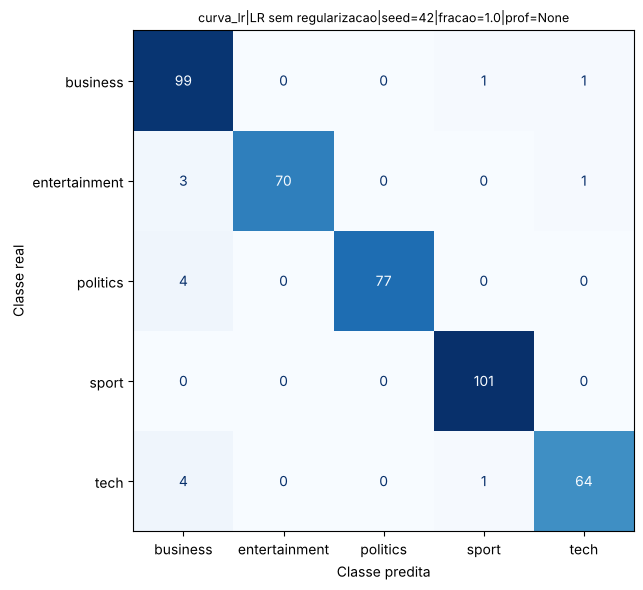

Principais confusões (qtd, real, predita): [(4, 'tech', 'business'), (4, 'politics', 'business'), (3, 'entertainment', 'business')]
Recall por classe: {'business': 0.9802, 'entertainment': 0.9459, 'politics': 0.9506, 'sport': 1.0, 'tech': 0.9275}


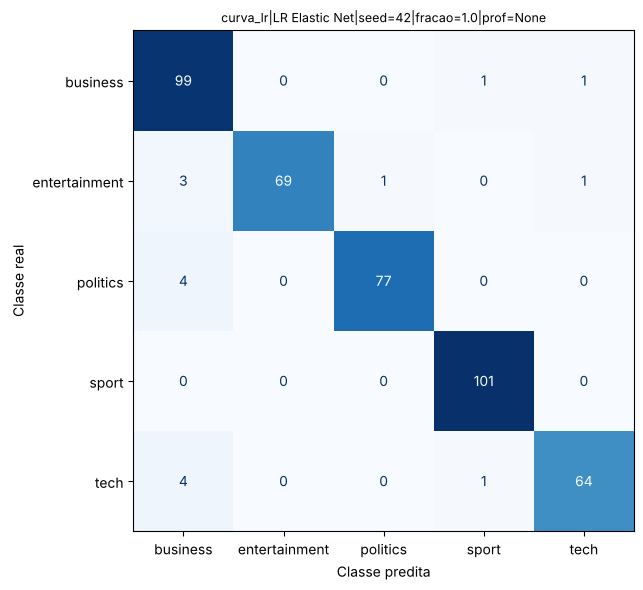

Principais confusões (qtd, real, predita): [(4, 'tech', 'business'), (4, 'politics', 'business'), (3, 'entertainment', 'business')]
Recall por classe: {'business': 0.9802, 'entertainment': 0.9324, 'politics': 0.9506, 'sport': 1.0, 'tech': 0.9275}


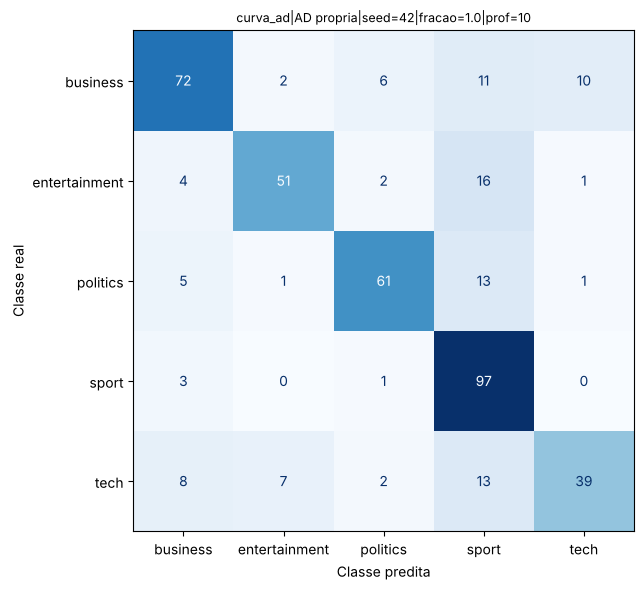

Principais confusões (qtd, real, predita): [(16, 'entertainment', 'sport'), (13, 'tech', 'sport'), (13, 'politics', 'sport')]
Recall por classe: {'business': 0.7129, 'entertainment': 0.6892, 'politics': 0.7531, 'sport': 0.9604, 'tech': 0.5652}


In [13]:
erros = []
for i, key in enumerate(selected, start=1):
    matrix = confusion_matrix(y_test, predictions[key], labels=CLASSES)
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).to_csv(OUT / f'confusao_{i}.csv')
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(key, fontsize=9); ax.set_xlabel('Classe predita'); ax.set_ylabel('Classe real'); ax.grid(False)
    fig.tight_layout(); fig.savefig(FIG / f'matriz_confusao_{i}.png', dpi=150); plt.show()
    pares = sorted([(int(matrix[a, b]), str(CLASSES[a]), str(CLASSES[b])) for a in range(len(CLASSES))
                    for b in range(len(CLASSES)) if a != b and matrix[a, b] > 0], reverse=True)[:3]
    recall = {str(c): round(float(r), 4) for c, r in zip(CLASSES, np.diag(matrix) / matrix.sum(axis=1))}
    erros.append((key, pares, recall))
    print('Principais confusões (qtd, real, predita):', pares)
    print('Recall por classe:', recall)

## 12. Relatório de resultados

Gera `resultados/relatorio_resultados.md` com os números desta execução.

In [14]:
sel = test_metrics.set_index('modelo_id').loc[selected]
L = ['# Resultados — BBC News', '',
     f'{len(raw)} notícias, {len(raw) - len(df)} duplicatas removidas → {len(df)}. Treino/validação/teste = '
     f'{len(train)}/{len(val)}/{len(test)}. TF-IDF com {MAX_FEATURES} termos + 2 atributos estruturados.', '',
     f'Alpha escolhido: {BEST_ALPHA}. Profundidade AD escolhida: {BEST_DEPTH}.', '',
     '## Modelos selecionados (teste)', '|Modelo|Precision macro|Recall macro|F1 micro|F1 macro|', '|---|---:|---:|---:|---:|']
L += [f'|{k}|{r.precision_macro:.4f}|{r.recall_macro:.4f}|{r.f1_micro:.4f}|{r.f1_macro:.4f}|' for k, r in sel.iterrows()]
L += ['', f'Baseline: F1 micro={baseline_scores["f1_micro"]:.4f}; F1 macro={baseline_scores["f1_macro"]:.4f}', '',
      '## Consistência', summary.round(4).to_markdown(index=False), '', '## Erros']
for key, pares, recall in erros:
    L += [f'- {key}: confusões {pares}; recall {recall}']
L += ['', '## Versões', json.dumps(VERSIONS)]
(OUT / 'relatorio_resultados.md').write_text('\n'.join(L), encoding='utf-8')
print('\n'.join(L))

# Resultados — BBC News

2225 notícias, 99 duplicatas removidas → 2126. Treino/validação/teste = 1275/425/426. TF-IDF com 1000 termos + 2 atributos estruturados.

Alpha escolhido: {'LR sem regularizacao': 0.0, 'LR Elastic Net': 1e-05, 'LR Lasso': 1e-05, 'LR Ridge': 0.0001}. Profundidade AD escolhida: 10.

## Modelos selecionados (teste)
|Modelo|Precision macro|Recall macro|F1 micro|F1 macro|
|---|---:|---:|---:|---:|
|curva_lr|LR sem regularizacao|seed=42|fracao=1.0|prof=None|0.9701|0.9609|0.9648|0.9647|
|curva_lr|LR Elastic Net|seed=42|fracao=1.0|prof=None|0.9675|0.9582|0.9624|0.9621|
|curva_ad|AD propria|seed=42|fracao=1.0|prof=10|0.7755|0.7362|0.7512|0.7444|

Baseline: F1 micro=0.2371; F1 macro=0.0767

## Consistência
| familia    |   fracao_treino |   n_treino |   treino_media |   validacao_media |   validacao_desvio |   gap_medio |
|:-----------|----------------:|-----------:|---------------:|------------------:|-------------------:|------------:|
| AD propria |             0.3 | 